# Student Academic Performance: From Prediction to Decision Support

**Research question:** *Can schools identify students who may fall below a project-defined final-grade benchmark, and does machine learning improve the way limited advising capacity is allocated compared with simple rules?*

This notebook extends the original team's exploratory ML work rather than replacing it. It reproduces results on the 395-row historical dataset, shows how predictive information becomes available at different stages, and tests a simulated advising queue.

**Important:** `G3 < 12` defines the *project's* at-risk outcome, not an official school-wide failing standard. No interventions or real decisions were deployed or measured. Predictions are not suitable for actual student-level decisions.

## Step 1. Inspect the problem and the raw dataset

**What we want to achieve:** Establish the number of records, missing values, class balance and the decision benchmark before modeling. Knowing the base rate prevents misleading interpretations of model accuracy.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from decision_support import read_data, analyze, STAGES, train_example, predict_risk

source = read_data(ROOT / "data" / "student_data.csv")
source["below_12"] = (source["G3/label_y"] < 12).astype(int)
print("Student records:", len(source))
print("Original variables:", len(source.columns) - 1)
print("Missing input cells:", source.isna().sum().sum())
print("Duplicate rows:", source.duplicated().sum())
print("Below project benchmark:", int(source["below_12"].sum()))
print("At or above benchmark:", int((1 - source["below_12"]).sum()))
display(source[["studytime", "failures", "G1", "G2", "G3/label_y", "below_12"]].head())

Student records: 395
Original variables: 33
Missing input cells: 0
Duplicate rows: 0
Below project benchmark: 233
At or above benchmark: 162


,studytime,failures,G1,G2,G3/label_y,below_12
0,2,0,5,6,6,1
1,2,0,5,5,6,1
2,2,3,7,8,10,1
3,3,0,15,14,15,0
4,2,0,6,10,10,1


**Observation:** The dataset contains **395 records and 33 original variables** with no missing cells or duplicate rows. There are **233** students below 12 and **162** at or above 12. A majority-class prediction already achieves about **59% accuracy**, so an ML model must be measured against this baseline.

## Step 2. Prevent data leakage and define prediction stages

**What we want to achieve:** Avoid asking an early-stage model to use information that would only be known later. We select a small, operational feature set and place all preprocessing inside each cross-validation fold.

The intake stage is only *provisional*: the dataset lacks timestamps proving exactly when survey answers were collected. Cumulative absences are **excluded entirely** because they may include information observed after the proposed decision date. Protected and family-demographic variables are excluded from the core models, but this does not guarantee fairness.

In [2]:
for stage, columns in STAGES.items():
    print(f"{stage}: {len(columns)} variables -> {', '.join(columns)}")

Intake survey (provisional): 8 variables -> traveltime, studytime, failures, schoolsup, famsup, paid, activities, higher
After first grade: 9 variables -> traveltime, studytime, failures, schoolsup, famsup, paid, activities, higher, G1
After second grade: 10 variables -> traveltime, studytime, failures, schoolsup, famsup, paid, activities, higher, G1, G2


**Observation:** Intake uses eight provisional survey variables; the first-grade stage adds `G1`, and the second-grade stage adds `G2`. Neither the final grade `G3` nor the full-period `absences` count is used to predict outcomes.

## Step 3. Evaluate alternative models using unseen-fold predictions

**What we want to achieve:** Compare a majority-class baseline, Logistic Regression and Random Forest for each stage. We use the same **5-fold StratifiedKFold** splits throughout. One-hot encoding and scaling are fitted within the training folds to avoid leakage.

Risk is the positive class (`1 = G3 < 12`). Alongside accuracy, calculate recall and precision for students below the benchmark, false alarms, missed-risk cases, ROC AUC and Brier probability loss.

In [3]:
results, oof_predictions, risk, capacity = analyze(source.drop(columns="below_12"))
headline_cols = ["stage", "method", "accuracy", "risk_precision", "risk_recall", "risk_f1", "missed_risk", "false_alarms", "brier_loss"]
display(results[results["method"].isin(["Majority class", "Logistic regression", "Random forest"])][headline_cols].round(3))

,stage,method,accuracy,risk_precision,risk_recall,risk_f1,missed_risk,false_alarms,brier_loss
0,Intake survey (provisional),Majority class,0.590,0.590,1.000,0.742,0.0,162.0,0.410
1,Intake survey (provisional),Logistic regression,0.600,0.662,0.657,0.660,80.0,78.0,0.222
2,Intake survey (provisional),Random forest,0.620,0.665,0.717,0.690,66.0,84.0,0.231
4,After first grade,Majority class,0.590,0.590,1.000,0.742,0.0,162.0,0.410
5,After first grade,Logistic regression,0.881,0.891,0.910,0.900,21.0,26.0,0.089
6,After first grade,Random forest,0.886,0.895,0.914,0.904,20.0,25.0,0.102
8,After second grade,Majority class,0.590,0.590,1.000,0.742,0.0,162.0,0.410
9,After second grade,Logistic regression,0.922,0.939,0.927,0.933,17.0,14.0,0.051
10,After second grade,Random forest,0.929,0.940,0.940,0.940,14.0,14.0,0.055


**Observation:** With only the survey-stage variables, Random Forest identifies around **71.7%** of below-benchmark students using a 0.5 classification cutoff, with approximately **62.0% accuracy**. After `G1` and `G2` become available, its accuracy rises to approximately **88.6%** and **92.9%**, respectively. The striking improvement with grade data means that a late-stage model should not be presented as a beginning-of-semester warning system.

## Step 4. Test the actual resource-allocation decision

**What we want to achieve:** Imagine advisors can review only **20%** of students (79 of 395). Rank cases using *out-of-fold* ML risk probabilities and compare them with simple, predetermined rules. For the intake survey, the rule prioritizes previous failures, then lower study time. For later stages, it prioritizes the lowest available prior-period grade.

This is a simulated prioritization exercise, **not** evidence that advising actually improves outcomes.

,stage,method,review_capacity,identified_in_top_20pct,top_20pct_precision,top_20pct_recall
0,Intake survey (provisional),Majority class,79,42,0.532,0.180
1,Intake survey (provisional),Logistic regression,79,65,0.823,0.279
2,Intake survey (provisional),Random forest,79,65,0.823,0.279
3,Intake survey (provisional),"Rule: previous failures, then study time",79,65,0.823,0.279
4,After first grade,Majority class,79,42,0.532,0.180
5,After first grade,Logistic regression,79,79,1.000,0.339
6,After first grade,Random forest,79,76,0.962,0.326
7,After first grade,Rule: lowest first-period grades,79,78,0.987,0.335
8,After second grade,Majority class,79,42,0.532,0.180
9,After second grade,Logistic regression,79,79,1.000,0.339


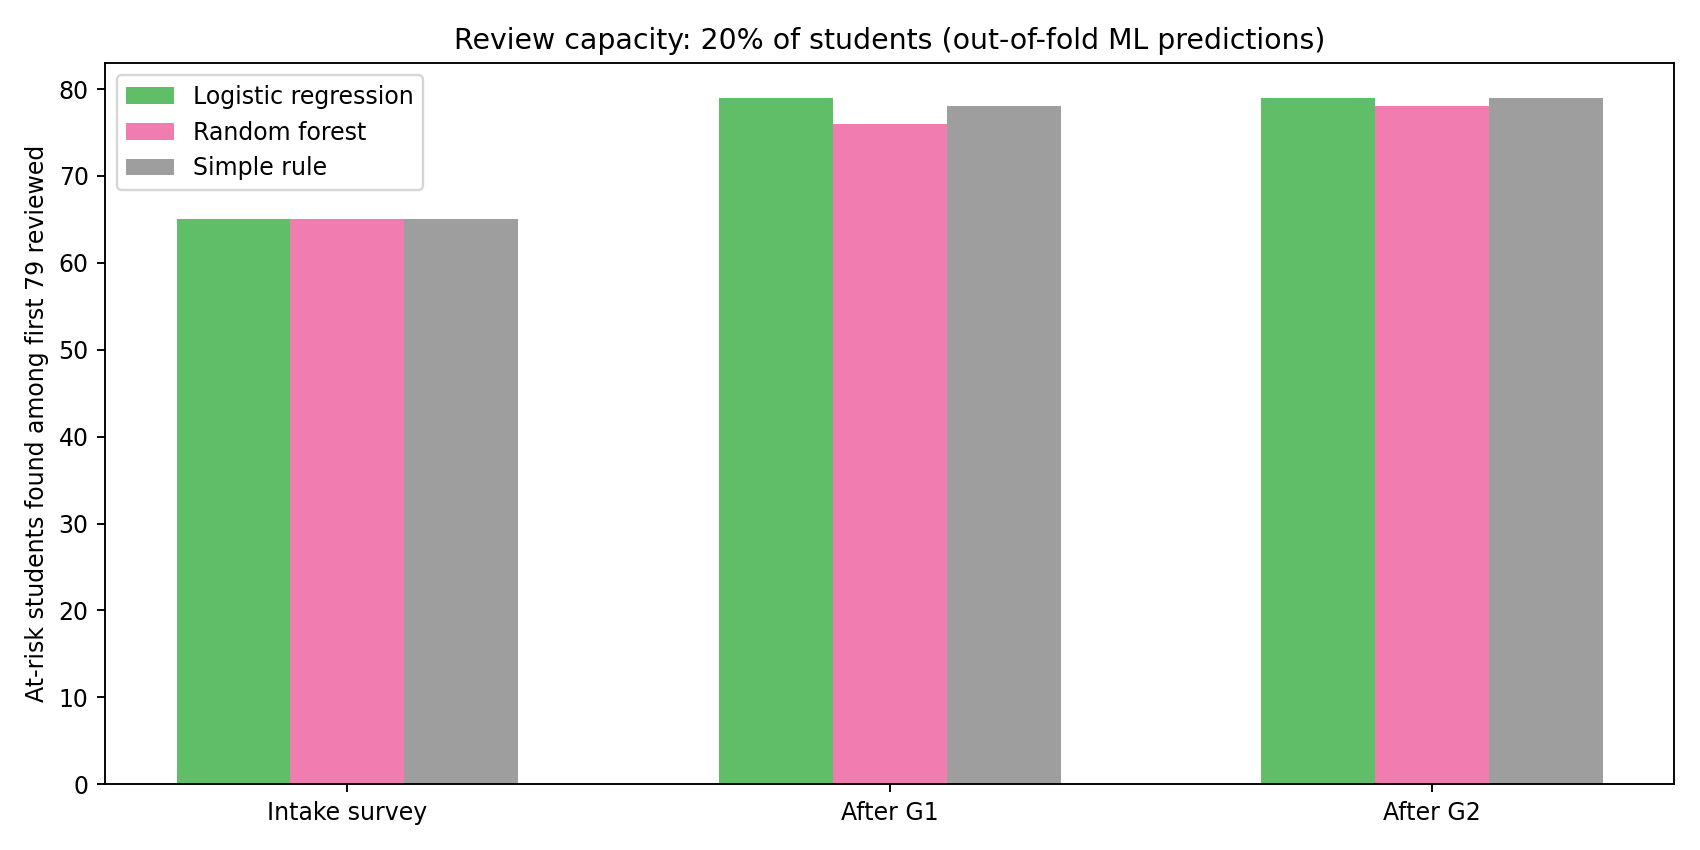

In [4]:
queue = results[["stage", "method", "review_capacity", "identified_in_top_20pct", "top_20pct_precision", "top_20pct_recall"]]
display(queue.round(3))
display(__import__("IPython").display.Image(filename=str(ROOT / "assets" / "review_capacity_comparison.png")))

**Observation:** Under the review-capacity scenario, the **simple grade-based rule can match or exceed the ML models** after grades become available. At intake, a previous-failures/study-time rule can also be competitive. The lesson is not to introduce a complex ML system unless it creates additional value over a transparent rule, for instance by improving performance across institutions or providing better uncertainty information.

## Step 5. Inspect model errors and probability quality

**What we want to achieve:** Separate mistakes made about the below-benchmark class from generic accuracy, and check whether predicted risk probabilities behave sensibly. We use out-of-fold probabilities; the original notebook's in-sample model-confidence chart should **not** be used as evidence of unseen-case reliability.

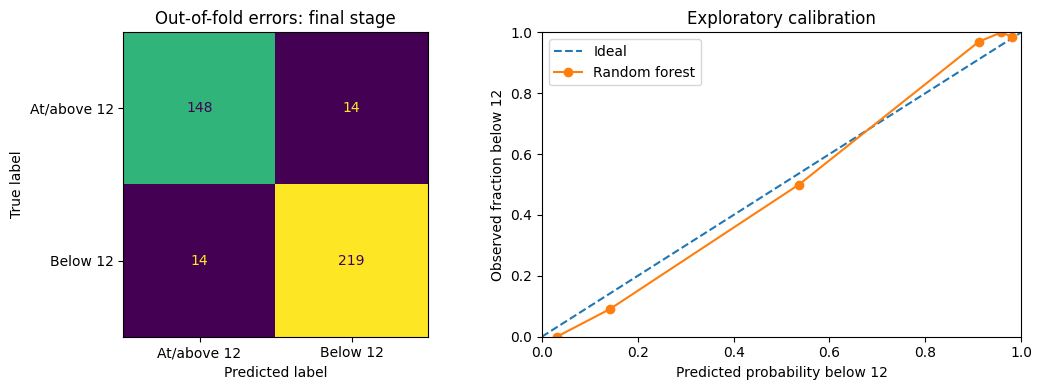

Confusion matrix [[true at/above, false alarm], [missed risk, true below]]: [[148, 14], [14, 219]]


In [5]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.calibration import calibration_curve
from sklearn.metrics import confusion_matrix

stage = "After second grade"
p = oof_predictions[(stage, "Random forest")]
classified = (p >= 0.5).astype(int)
cm = confusion_matrix(risk, classified, labels=[0, 1])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(cm, display_labels=["At/above 12", "Below 12"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Out-of-fold errors: final stage")
frac, avg_p = calibration_curve(risk, p, n_bins=6, strategy="quantile")
axes[1].plot([0,1],[0,1], linestyle="--", label="Ideal")
axes[1].plot(avg_p, frac, marker="o", label="Random forest")
axes[1].set(xlim=(0,1), ylim=(0,1), xlabel="Predicted probability below 12", ylabel="Observed fraction below 12", title="Exploratory calibration")
axes[1].legend(); plt.tight_layout(); plt.show()
print("Confusion matrix [[true at/above, false alarm], [missed risk, true below]]:", cm.tolist())

**Observation:** The second-grade Random Forest misses **14** below-benchmark students and creates **14** false alarms at the 0.5 classification threshold in out-of-fold predictions. The reliability plot is **exploratory** because the sample is small and folds are reused for comparing alternatives; calibration is not established for other schools or years.

## Step 6. Document a limited fairness and generalization audit

**What we want to achieve:** Examine error rates by existing groups for research transparency. These variables were **not** used to train the core model. Small sample sizes and underlying differences mean group results are descriptive, not proof of fairness.

In [6]:
from sklearn.metrics import recall_score
for group in ["sex", "school"]:
    print(f"\nDescriptive audit by {group} (held-out-fold predictions):")
    rows=[]
    for label, idx in source.groupby(group).groups.items():
        inds=np.asarray(sorted(idx))
        yy=risk[inds]; pp=classified[inds]
        rows.append({"group":str(label),"n":len(inds),"risk_rate":round(float(yy.mean()),3),
                     "risk_recall":round(float(recall_score(yy, pp,zero_division=0)),3),
                     "errors":int((yy != pp).sum())})
    display(pd.DataFrame(rows))


Descriptive audit by sex (held-out-fold predictions):


,group,n,risk_rate,risk_recall,errors
0,F,208,0.644,0.948,12
1,M,187,0.529,0.929,16



Descriptive audit by school (held-out-fold predictions):


,group,n,risk_rate,risk_recall,errors
0,GP,349,0.579,0.946,24
1,MS,46,0.674,0.903,4


**Observation:** Error rates can vary across demographic and school groups even when those attributes are removed from training. This descriptive audit is not a fairness certification; a deployable system would need consent, governance, representative external data, subgroup validation, and human oversight.

## Step 7. Demonstrate local prediction as a software-delivery component

**What we want to achieve:** Package the model together with its encoders and imputers so a future application could process a new structured record consistently. This example fits an illustrative model on all 395 records **after** cross-validation, strictly for local software testing. Do not treat the resulting predictions as validated outcomes.

In [7]:
import joblib
pipeline = joblib.load(ROOT / "models" / "academic_risk_pipeline.joblib")
example = source.iloc[0][STAGES["After second grade"]].to_dict()
probability = predict_risk(pipeline, example)
print(f"Demonstration model probability below 12: {probability:.3f}")
print("No student-specific decisions or interventions are triggered.")

Demonstration model probability below 12: 0.964
No student-specific decisions or interventions are triggered.


**Observation:** The saved pipeline accepts the original categorical and numerical feature values and returns a probability without manually reproducing one-hot encoding. This demonstrates a reusable inference component. It is **not yet an AWS deployment**, an independently validated model, or evidence of real-world impact.

## Step 8. Recommendations, limits, and next actions

**Recommendations from this analysis:**

1. **Prioritize simple and transparent rules when they perform just as well.** In this dataset, ranking by the most recent prior grade was especially effective for a fixed-size review queue.
2. **Report prediction timing.** `G2`-based accuracy is not equivalent to an early-semester intervention opportunity.
3. **Use ML as an investigated alternative, not an assumed improvement.** If institutions want richer risk estimation, evaluate models prospectively against existing decision processes and calibration criteria.
4. **Keep a human in the loop.** A risk score should never automatically penalize or label a student.

**Limitations:** A small historical dataset from Portuguese secondary schools, uncertain feature availability timing, project-defined 12/20 cutoff, possible proxies for sensitive attributes, selected models compared on the same cross-validation dataset, no independent or external validation, no real advisor capacity data, and no measured impact on grades or retention.

**Next:** Obtain timestamped data and an institution-approved threshold; validate prospectively; test capacity and subgroup tradeoffs with advisors; measure whether any intervention improves outcomes. A cloud demo may demonstrate software delivery but will not fix these evidence gaps.